# Import Library

In [1]:
import openmc
from math import sqrt, sin, cos, pi, atan, tan, acos, ceil
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

/home/azma/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
os.environ['OPENMC_CROSS_SECTIONS'] = '/home/azma/endfb71/endfb-vii.1-hdf5/cross_sections.xml'

In [3]:
path_xml = os.environ.get('OPENMC_CROSS_SECTIONS')
print(f"Lokasi Library: {path_xml}")

Lokasi Library: /home/azma/endfb71/endfb-vii.1-hdf5/cross_sections.xml


# Material
## Fuel

In [4]:
wo_U233 = 10/100
wo_U238 = 1 - wo_U233

n_U233 = wo_U233/233
n_U238 = wo_U238/238
n_U_total = n_U233 + n_U238

ao_U233 = n_U233/n_U_total
ao_U238 = 1 - ao_U233

UF4 = openmc.Material(name = "UF4")
UF4.add_nuclide("U233",ao_U233,"ao")
UF4.add_nuclide("U238",ao_U238,"ao")

In [5]:
ThF4 = openmc.Material(name = "ThF4")
ThF4.add_element("Th",1,"ao")
ThF4.add_element("F",4,"ao")

In [6]:
fuel = openmc.Material.mix_materials(
    materials = [UF4, ThF4],
    fracs = [0.2194, 0.7806], percent_type = 'ao'
)

## Salt

In [7]:
LiF = openmc.Material(name = "LiF")
LiF.add_element("F", 1, "ao")
LiF.add_element("Li", 1, "ao")

In [8]:
BeF2 = openmc.Material(name = "BeF2")
BeF2.add_element("F", 2, "ao")
BeF2.add_element("Be", 1, "ao")

In [9]:
molten_salt = openmc.Material.mix_materials(
    materials = [LiF, BeF2],
    fracs = [0.632, 0.368], percent_type = 'ao'
)

In [10]:
MSR_fuel = openmc.Material.mix_materials(
    materials = [fuel, molten_salt],
    fracs = [0.278, 0.722], percent_type = 'ao'
)
MSR_fuel.set_density("g/cm3", 3.228)

## Moderator

In [11]:
graphite = openmc.Material(name = "Graphite")
graphite.add_element("C",1,"ao")
graphite.set_density("g/cm3",2.2)

## Shield

In [12]:
wo_Fe = 69/100
wo_Cr = 19/100
wo_Mn = 1.55/100
wo_Ni = 9/100
wo_C = 0.08/100
wo_Si = 1 - (wo_Fe + wo_Cr + wo_Mn + wo_Ni + wo_C)

ss304 = openmc.Material(name = "Stainless Stell 304")
ss304.add_element('Fe', wo_Fe, percent_type='wo')
ss304.add_element('Cr', wo_Cr, percent_type='wo')
ss304.add_element('Mn', wo_Mn, percent_type='wo')
ss304.add_element('Ni', wo_Ni, percent_type='wo')
ss304.add_element('C', wo_C, percent_type='wo')
ss304.add_element('Si', wo_Si, percent_type='wo')
ss304.set_density('g/cm3', 7.9)

In [13]:
materials = openmc.Materials(materials = [MSR_fuel, graphite, ss304])
materials.export_to_xml()

# Geometry

In [14]:
#batas atas dan bawah fuel
bot = -178
top = 178

bot_boundary = openmc.ZPlane(z0 = bot, boundary_type = "vacuum")
top_boundary = openmc.ZPlane(z0 = top, boundary_type = "vacuum")

## Pin Fuel

In [15]:
r_fuel = 4 #cm, jari jari tabung bahan bakar

cylinder_infinite = openmc.ZCylinder(
    r = r_fuel,
    boundary_type = "transmission"
)

cylinder_fuel = -cylinder_infinite & +bot_boundary & -top_boundary

#tabung bahan bakar
fuel_cell = openmc.Cell()
fuel_cell.region = cylinder_fuel
fuel_cell.fill = MSR_fuel

In [16]:
hexagon_in = 2/sqrt(3) * 10 #cm, panjang sisi hexagon
hexagon_out = 2/sqrt(3) * (10 + 0.2) #cm

hexagon_infinite_in = openmc.model.HexagonalPrism(
    edge_length = hexagon_in,
    boundary_type = "transmission",
    orientation = 'x'
)

hexagon_infinite_out = openmc.model.HexagonalPrism(
    edge_length = hexagon_out,
    boundary_type = "transmission",
    orientation = 'x'
)

#moderator hexagon
hexagon_graphite = -hexagon_infinite_in & +bot_boundary & -top_boundary & +cylinder_infinite
graphite_cell = openmc.Cell()
graphite_cell.region = hexagon_graphite
graphite_cell.fill = graphite

#gap antar 2 pin
gap = -hexagon_infinite_out & +hexagon_infinite_in
gap_cell = openmc.Cell()
gap_cell.region = gap
gap_cell.fill = MSR_fuel

In [17]:
pin_universe = openmc.Universe(cells = [fuel_cell, graphite_cell, gap_cell])
geom = openmc.Geometry(root = pin_universe)
geom.export_to_xml()

In [18]:
color = {MSR_fuel : "yellow", graphite : "purple"}

p1 = openmc.Plot()
p1.basis = "xy"
p1.origin = (0,0,0)
p1.width = (25, 25)
p1.pixels = (2000,2000)
p1.color_by = "material"
p1.colors = color

p2 = openmc.Plot()
p2.basis = "yz"
p2.origin = (0,0,0)
p2.width = (500, 30)
p2.pixels = (2000,2000)
p2.color_by = "material"
p2.colors = color

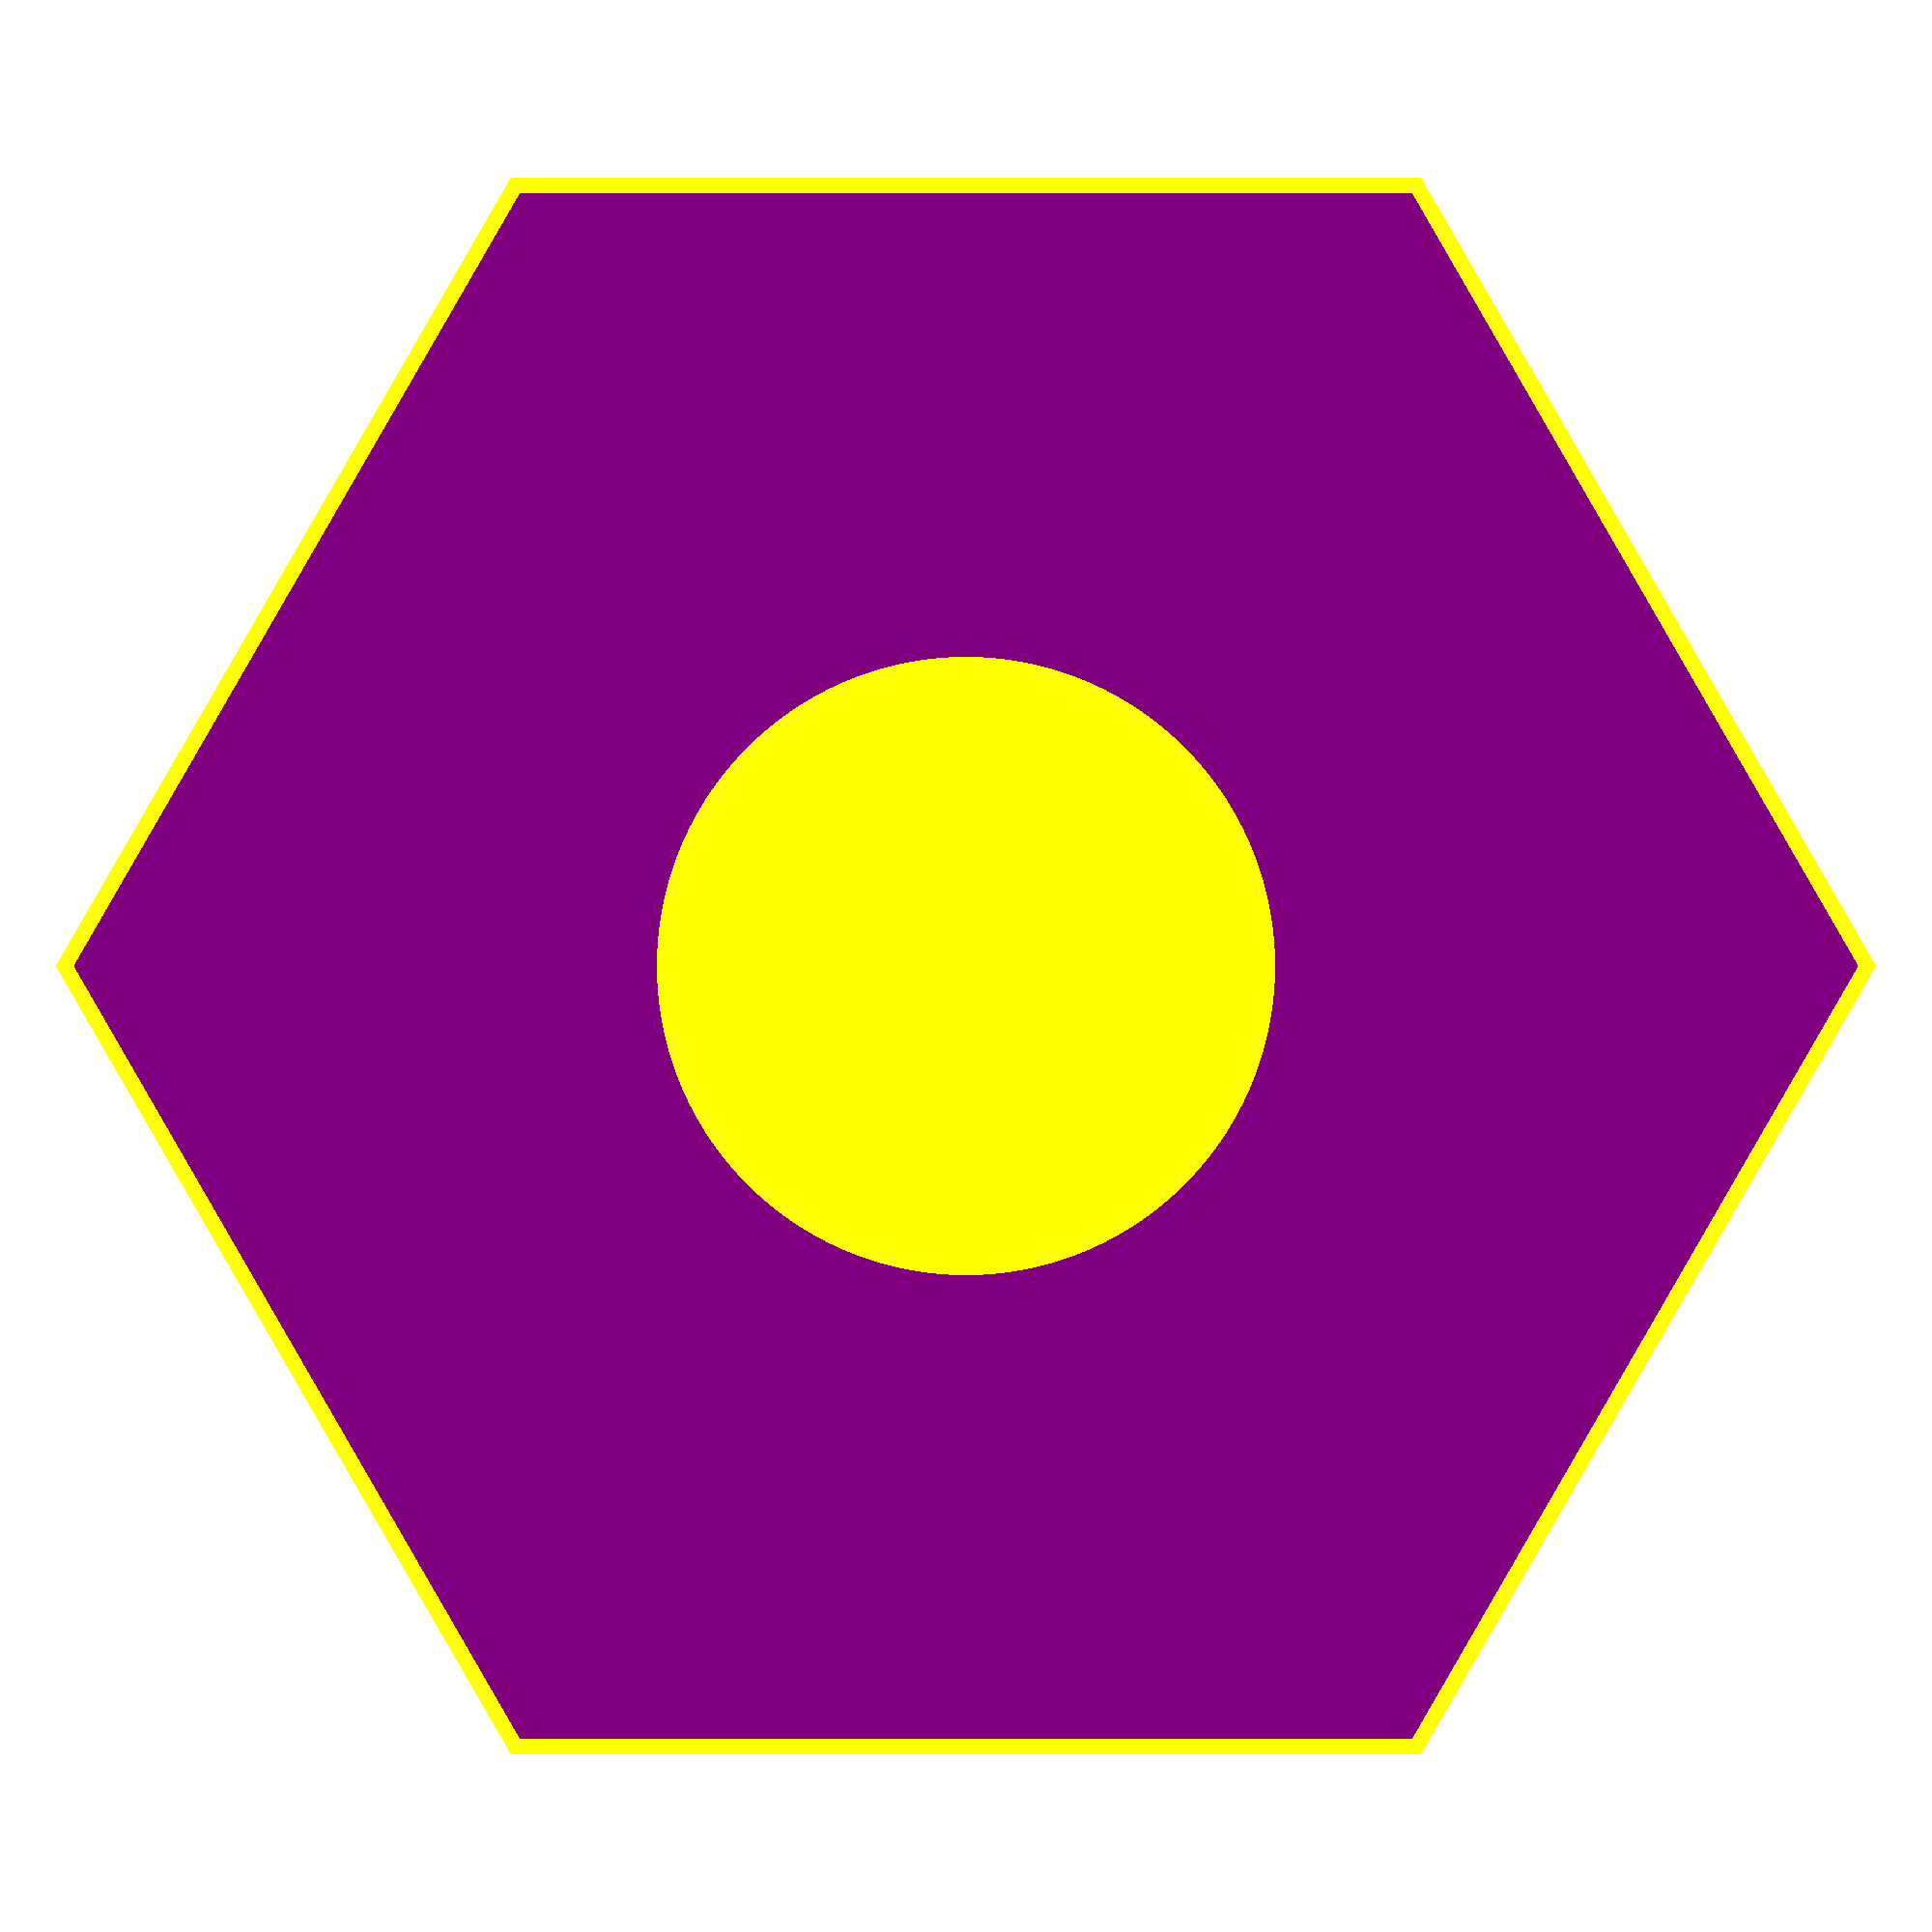

In [19]:
p1.to_ipython_image()

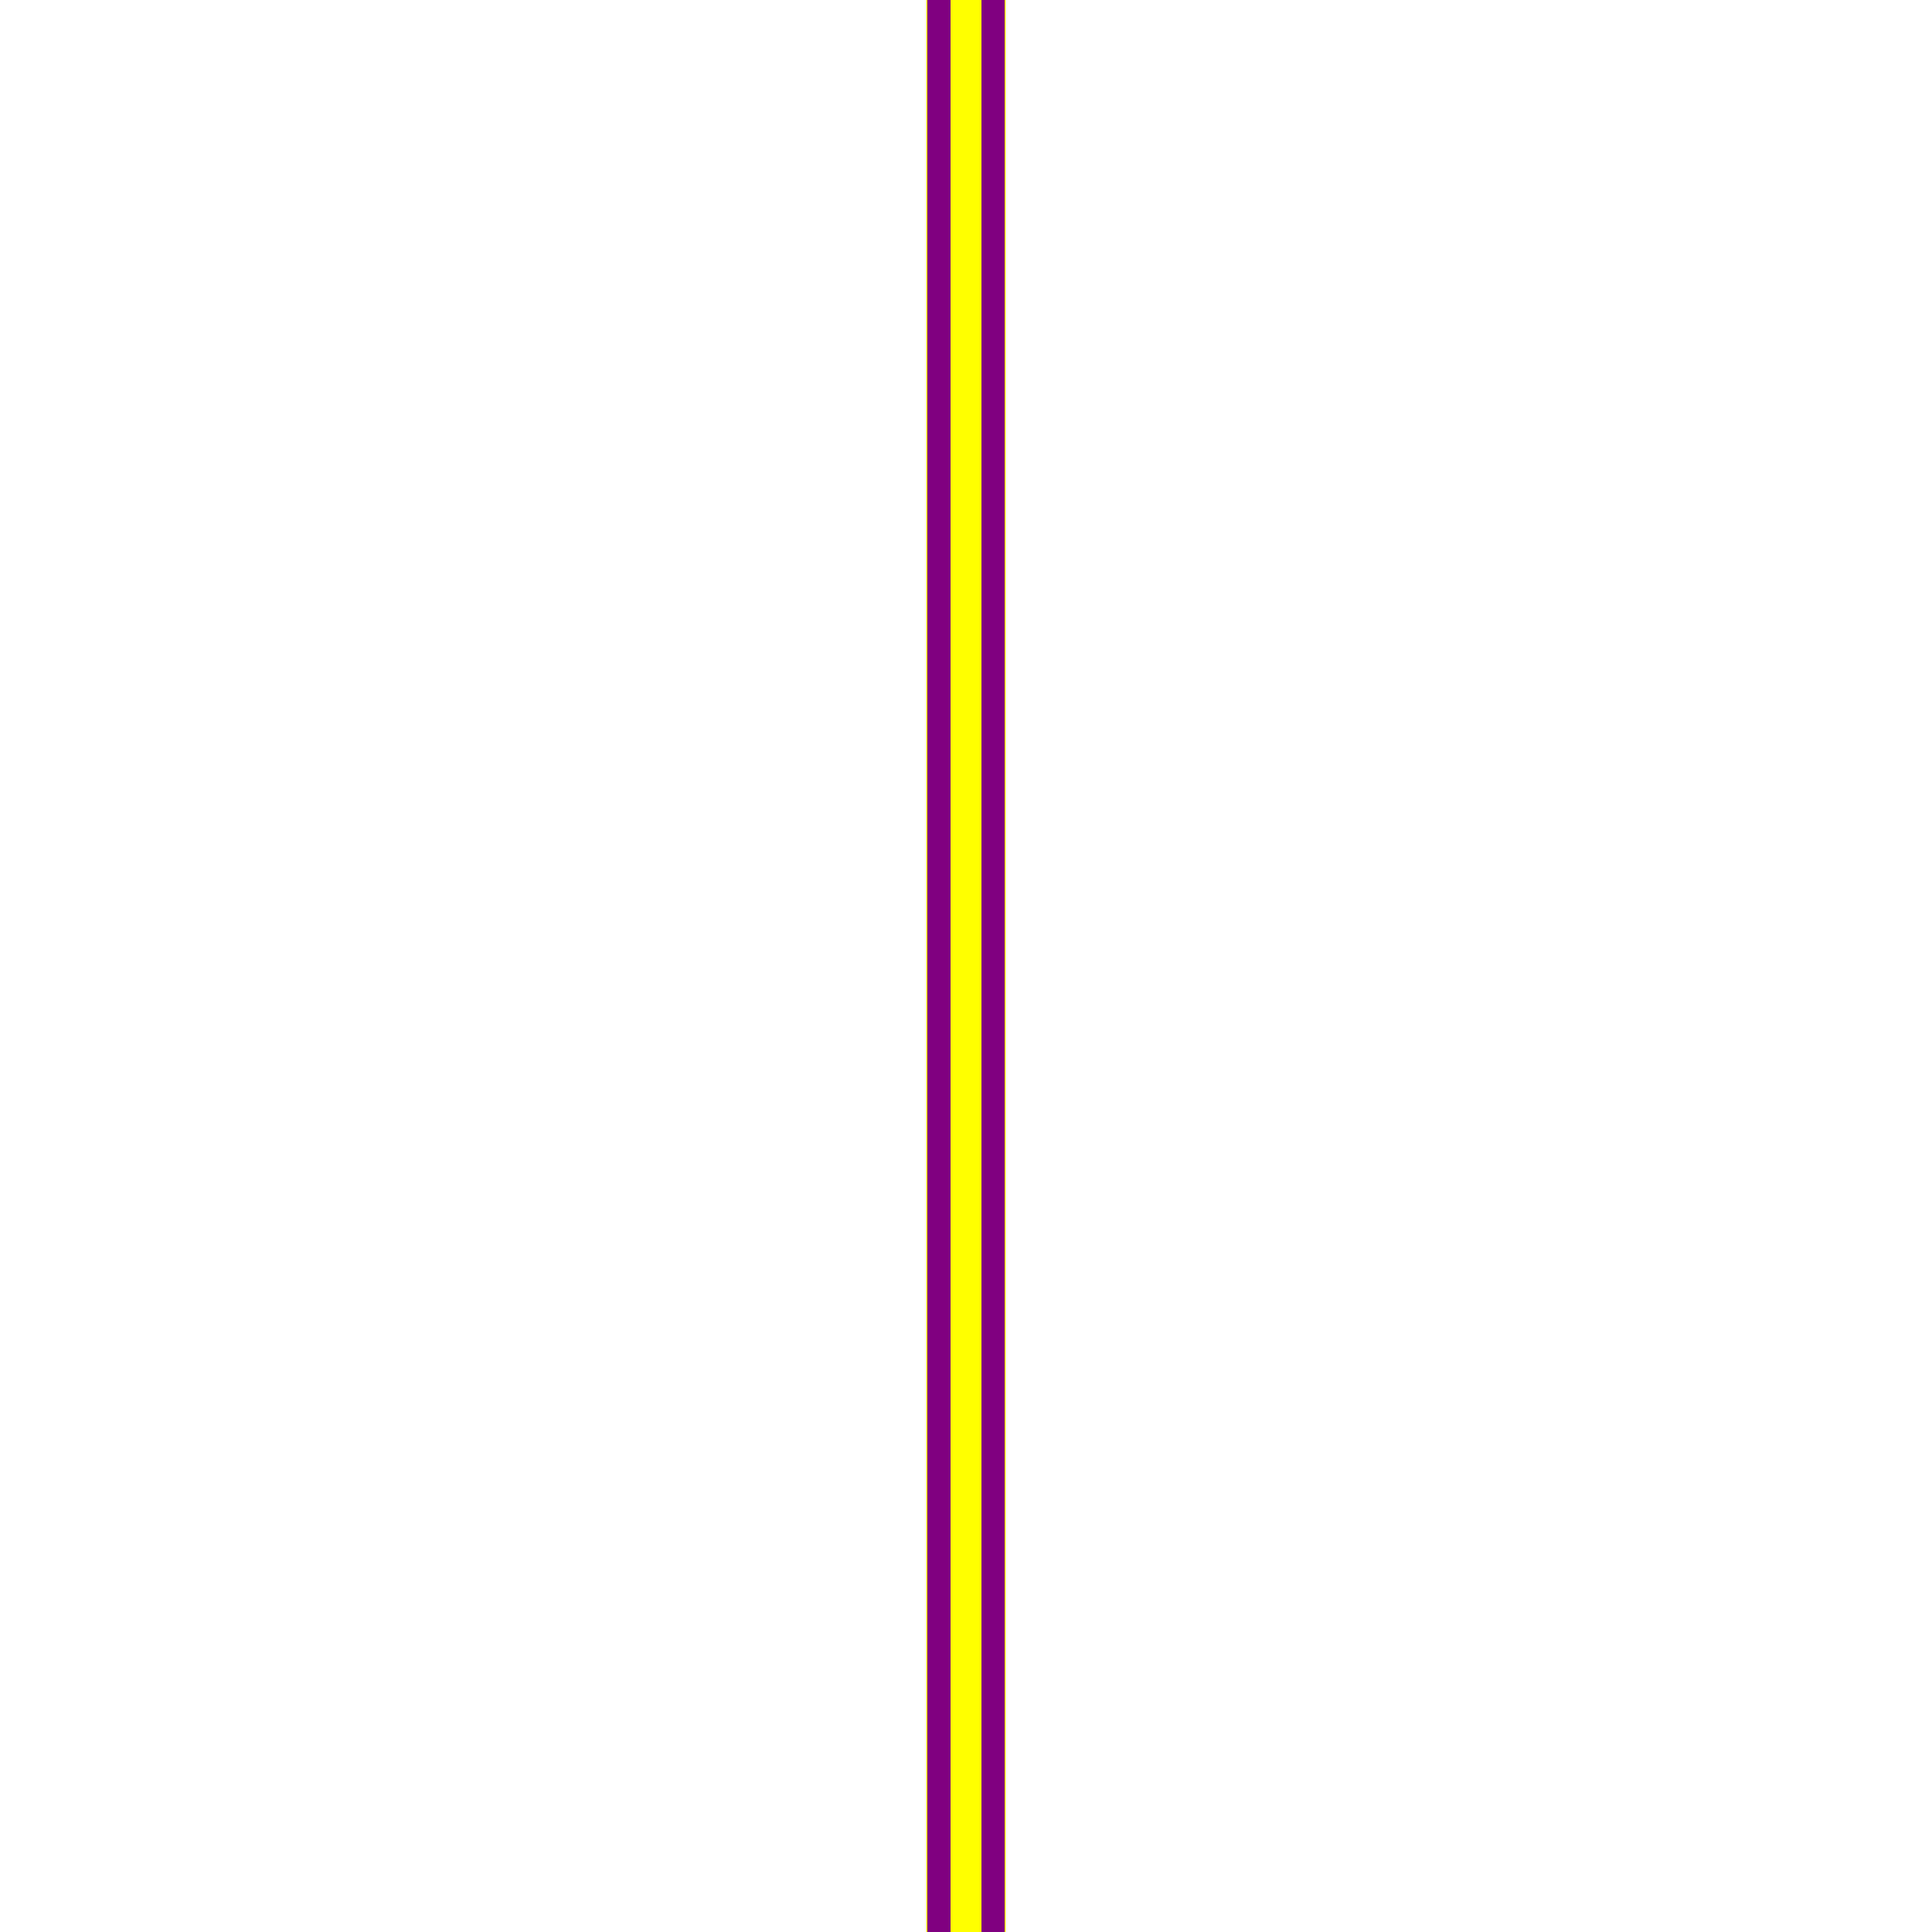

In [20]:
p2.to_ipython_image()

## Container

In [21]:
r_container_in = 177.54
barrier = 5

r_container_out = r_container_in + barrier

cylinder_in = openmc.ZCylinder(
    r = r_container_in,
    boundary_type = "reflective"
)

cylinder_out = openmc.ZCylinder(
    r = r_container_out,
    boundary_type = "reflective"
)

#cladding steel
cladding_region = +cylinder_in & -cylinder_out & +bot_boundary & -top_boundary
cladding_cell = openmc.Cell()
cladding_cell.region = cladding_region
cladding_cell.fill = ss304

In [22]:
dome_height = 10 #cm, tinggi dome

alpha = atan(r_container_in/dome_height) #sudut elips

#jari jari kubah
r_dome_in = ((dome_height/cos(alpha))/2)/cos(alpha)
r_dome_out = r_dome_in + barrier

#posisi titik pusat sphere (dome) dalam sumbu Z
y = sqrt(r_dome_in**2 - r_container_in**2)
z_top = top - y

dome_in_top = openmc.Sphere(
    r = r_dome_in,
    z0 = z_top
)

dome_out_top = openmc.Sphere(
    r = r_dome_out,
    z0 = z_top
)

#kubah baja atas
dome_top_reg = +dome_in_top & -dome_out_top & +top_boundary & -cylinder_out
dome_top = openmc.Cell()
dome_top.region = dome_top_reg
dome_top.fill = ss304

#kubah fuel atas
dome_fill_top_reg = -dome_in_top & + top_boundary
dome_fill_top = openmc.Cell()
dome_fill_top.region = dome_fill_top_reg
dome_fill_top.fill = MSR_fuel

In [23]:
z_bot = bot + y

dome_in_bot = openmc.Sphere(
    r = r_dome_in,
    z0 = z_bot
)

dome_out_bot = openmc.Sphere(
    r = r_dome_out,
    z0 = z_bot
)

#kubah baja bawah
dome_bot_reg = +dome_in_bot & -dome_out_bot & -bot_boundary & -cylinder_out
dome_bot = openmc.Cell()
dome_bot.region = dome_bot_reg
dome_bot.fill = ss304

#kubah fuel bawah
dome_fill_bot_reg = -dome_in_bot & -bot_boundary
dome_fill_bot = openmc.Cell()
dome_fill_bot.region = dome_fill_bot_reg
dome_fill_bot.fill = MSR_fuel

## Lattice

In [24]:
#definisi "kosong" pada lattice (isi graphite coy)
no_fuel_area = -hexagon_infinite_out & +bot_boundary & -top_boundary
no_fuel_cell = openmc.Cell()
no_fuel_cell.region = no_fuel_area
no_fuel_cell.fill = graphite

no_fuel_pin = openmc.Universe(cells=[no_fuel_cell])

In [25]:
lattice = openmc.HexLattice()

lattice.center = (0., 0.)
lattice.pitch = (20.2,)

In [26]:
num_rings = 12  #banyak ring lattice
ring_inactive = 2  #banyak ring "kosong" dari pin bahan bakar
universes = []

for i in range(num_rings):
    if i < (num_rings - 1):
        num_pins_in_ring = 6 * (num_rings - 1 - i)
        if i == ring_inactive:
            ring = ([no_fuel_pin]*3 + [pin_universe]*(num_pins_in_ring//6 - 5) + [no_fuel_pin]*2)*6
        elif i <= ring_inactive:
            ring = [no_fuel_pin] * num_pins_in_ring
        else:
            ring = [pin_universe] * num_pins_in_ring
    else:
        ring = [pin_universe]
    universes.append(ring)
lattice.universes = universes

In [27]:
#kontainer utama (ini gong nya)
main_region = -cylinder_in & +bot_boundary & -top_boundary
main_cylinder = openmc.Cell()
main_cylinder.region = main_region
main_cylinder.fill = lattice

In [28]:
universe = openmc.Universe(cells = [
    cladding_cell,  
    main_cylinder,
    dome_top,
    dome_fill_top,
    dome_bot,
    dome_fill_bot
])

geometry = openmc.Geometry(root = universe)
geometry.export_to_xml()

In [29]:
color2 = {MSR_fuel : "yellow", graphite : "purple", ss304: 'grey'}

p3 = openmc.Plot.from_geometry(geometry)
p3.basis = "xy"
p3.origin = (0,0,0)
p3.width = (450, 450)
p3.pixels = (5000,5000)
p3.color_by = "material"
p3.colors = color2

p4 = openmc.Plot.from_geometry(geometry)
p4.basis = "yz"
p4.origin = (0,0,0)
p4.width = (500, 500)
p4.pixels = (5000, 5000)
p4.color_by = "material"
p4.colors = color2

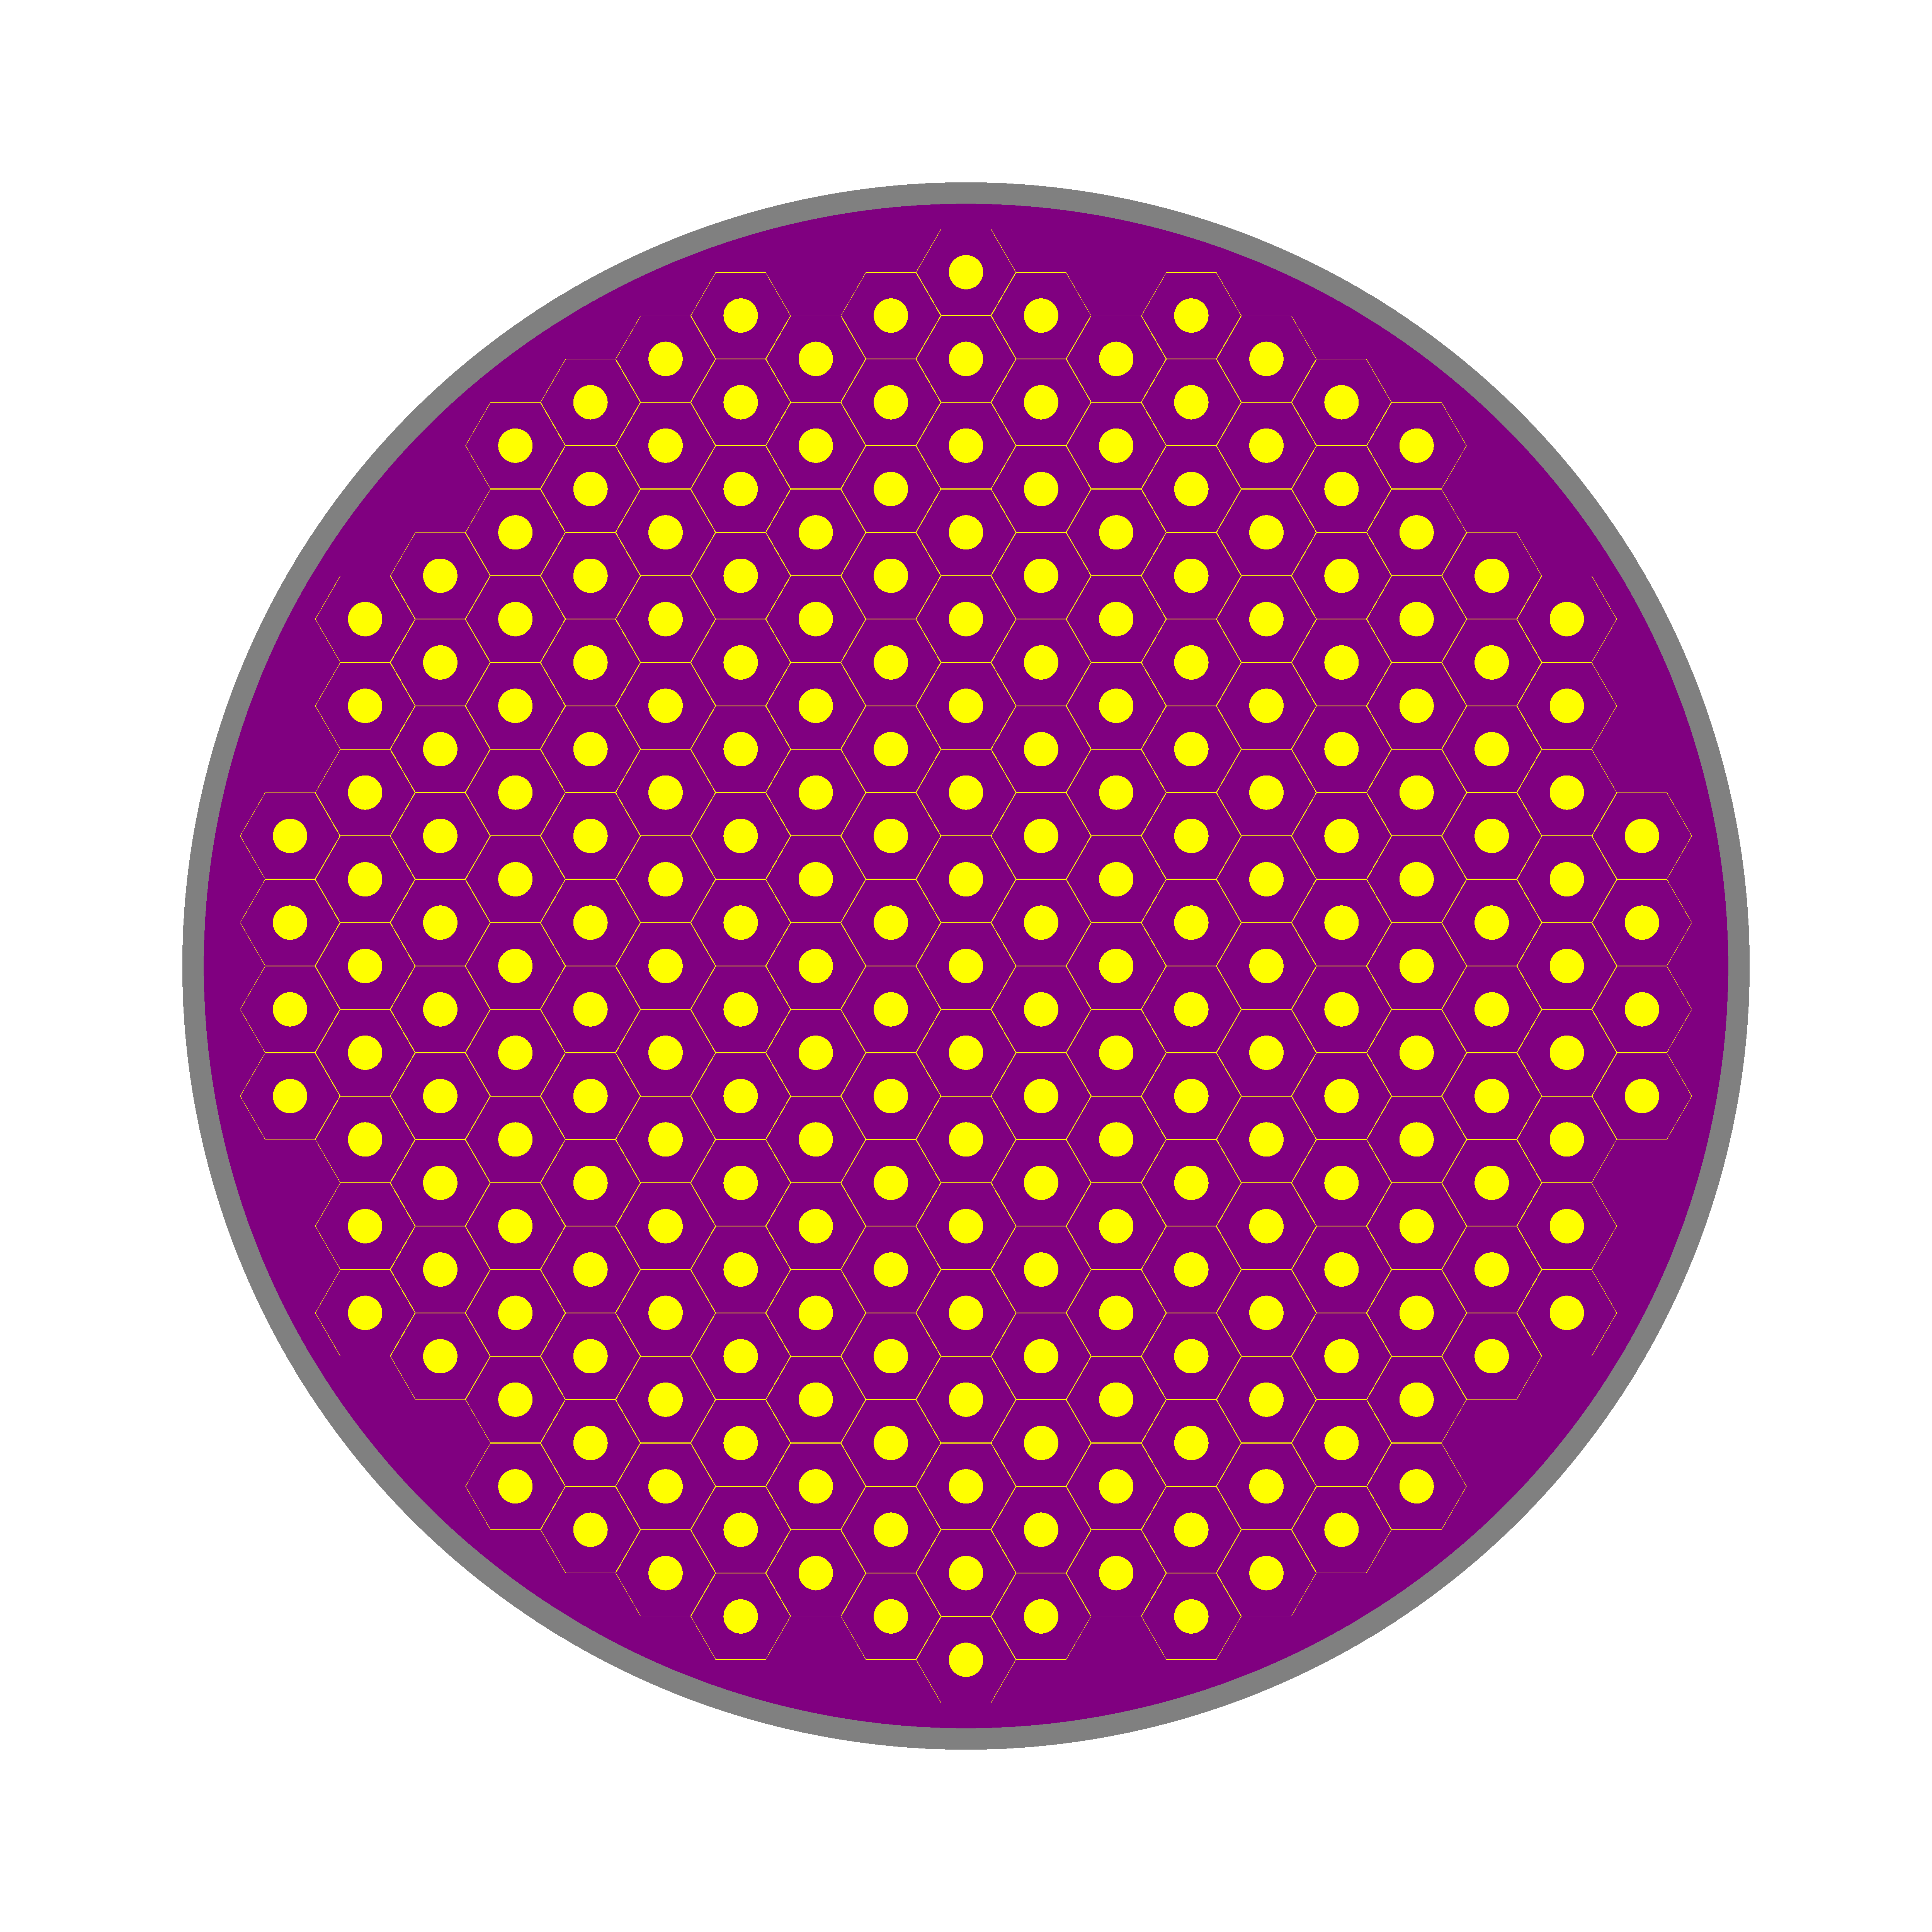

In [30]:
p3.to_ipython_image()

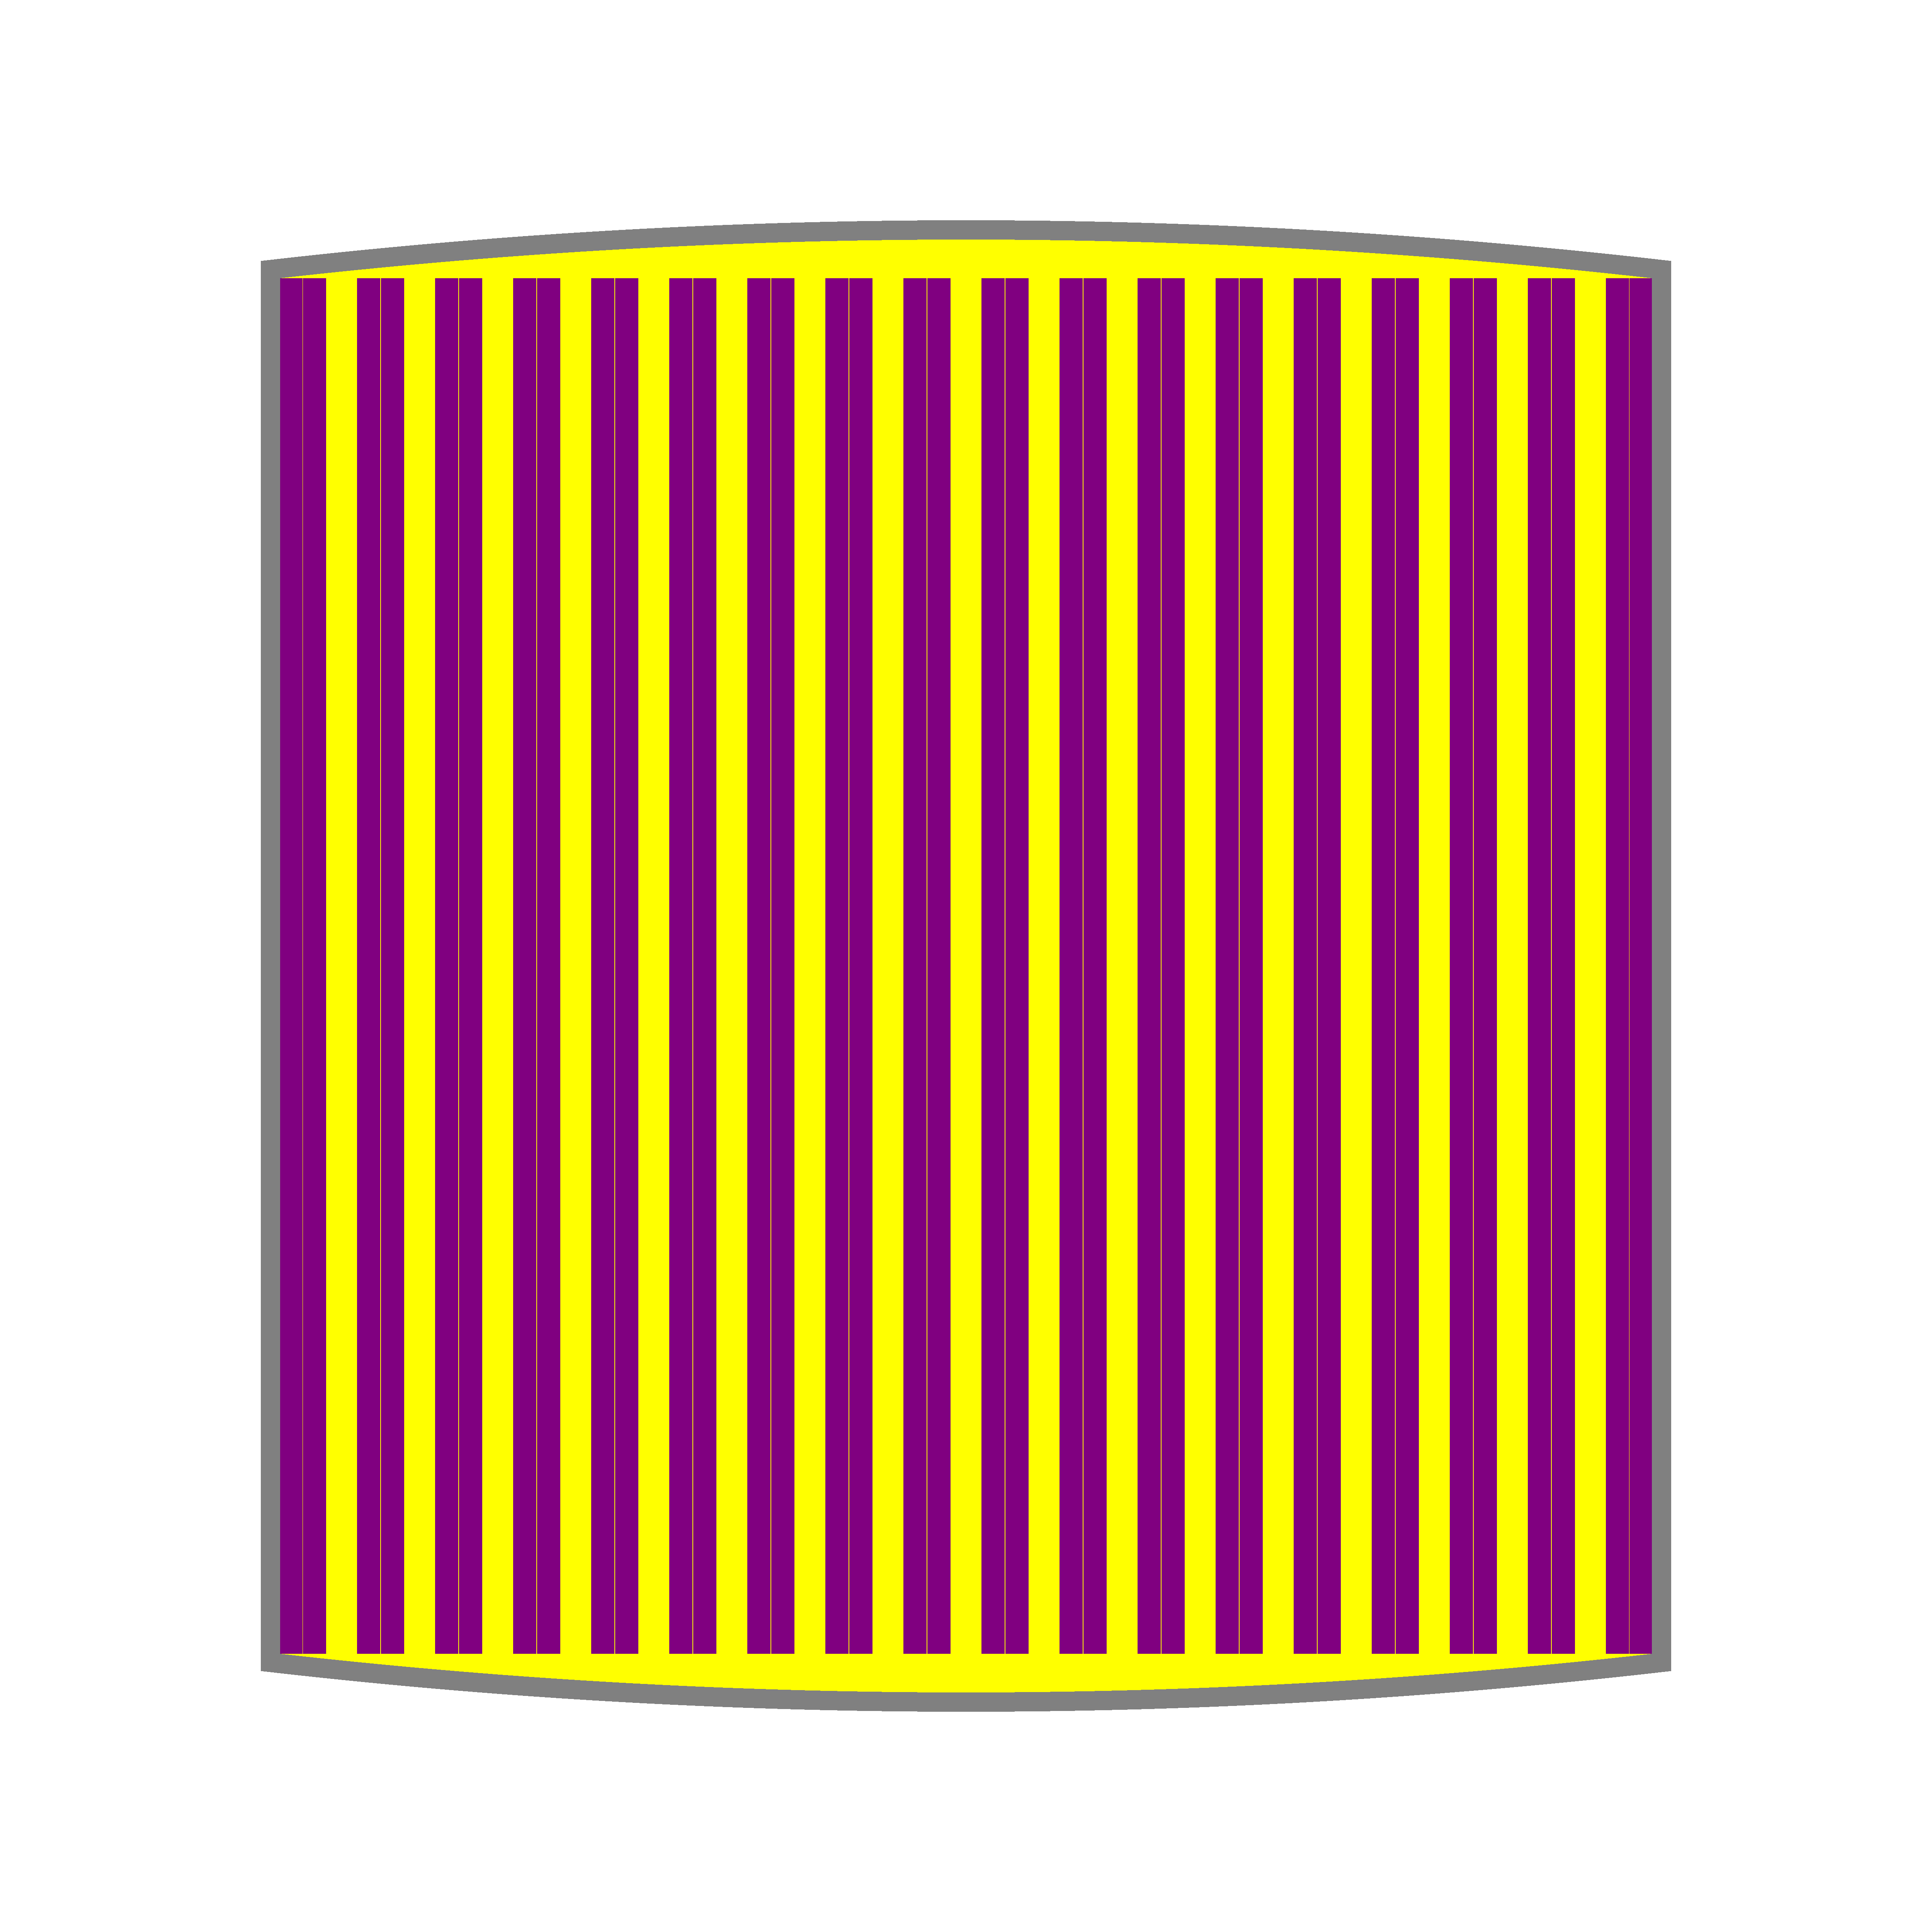

In [31]:
p4.to_ipython_image()

# $K_{eff}$ at $T_{fuel}$ 900 K

In [32]:
coord = (0, 0, 0)
point = openmc.stats.Point(coord)
source = openmc.IndependentSource(
    space = point,
    constraints={'fissionable': True}
)

fuel.temperature = 900

settings = openmc.Settings()
settings.source = source
settings.batches = 200
settings.inactive = 50
settings.particles = 10300
settings.temperature = {
        'method': 'interpolation',
        'tolerance': 10.0
    }
#settings.entropy_mesh = mesh
settings.export_to_xml()

openmc.run(output=False)

RuntimeError: Cross sections XML file '/home/azma/endfb71/endfb-vii.1-hdf5/cross_sections.xml' does not exist.

In [33]:
sp = openmc.StatePoint('statepoint.200.h5')
k_normal = sp.keff.n
k_uncertain = sp.keff.s  #standar dev

print(f'nilai k_eff ketika suhu bahan bakar 900 K adalah {k_normal:4f} +- {k_uncertain:4f}')

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'statepoint.200.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
os.remove('statepoint.200.h5')
os.remove('summary.h5')

# Fuel Temperature Coefficient

In [ ]:
P = []
T_fuel = []  #suhu bahan bakar
for temp in range (800, 1050, 50):
    fuel.temperature = temp
    openmc.run(output=False)
    
    sp2 = openmc.StatePoint('statepoint.200.h5')
    k_eff = sp2.keff.n
    P_temp = (k_eff - 1) / k_eff
    P.append(P_temp)
    T_fuel.append(temp)
    
    os.remove('statepoint.200.h5')
    os.remove('summary.h5')

In [ ]:
plt.plot(T_fuel, P)
plt.title('')
plt.xlabel('Fuel Temperature (K)')
plt.ylabel('P')
plt.grid()
plt.show()

# Void Coefficient

In [ ]:
V = []  #void persentase
k_eff = []

for void_perc in range (0, 12, 2):
    void_fract = void_perc / 100
    V.append(void_perc)
    
    P_void = MSR_fuel.density * (1 - void_fract)
    MSR_fuel.set_density('g/cm3', P_void)
    
    materials.export_to_xml()
    geometry.export_to_xml()
    settings.export_to_xml()
    
    openmc.run(output=False)
    
    sp3 = openmc.StatePoint('statepoint.200.h5')
    k = sp3.keff.n
    k_eff.append(k)
    
    os.remove('statepoint.200.h5')
    os.remove('summary.h5')

void_coeff = ["-"]

for i in range (len(k_eff) - 1):
    delta_k = k_eff[i+1] - k_eff[i]
    delta_v = V[i+1] - V[i]
    
    void_coeff.append(delta_k / delta_v)

In [ ]:
print("void(%)     k_eff       void coeff")
print("="*35)

for i in range (len(V)):
    if i == 0:
        print(f'{V[i]:4} {k_eff[i]:15.6f} {void_coeff[i]:>4}')
    else:
        print(f'{V[i]:4} {k_eff[i]:15.6f} {void_coeff[i]:12.6f}')

In [ ]:
plt.plot(V, k_eff)
plt.title('')
plt.xlabel('void percentage (%)')
plt.ylabel('delta k')
plt.grid()
plt.show()

# Convertion Ratio

In [ ]:
fuel_filter = openmc.MaterialFilter([MSR_fuel])

fertile_prod = openmc.Tally(name = 'fertile capture')
fertile_prod.filters = [fuel_filter]
fertile_prod.nuclides = ['U238', 'Th232']
fertile_prod.scores = ['(n,gamma)']

fissile_cons = openmc.Tally(name = 'fissile fission')
fissile_cons.filters = [fuel_filter]
fissile_cons.nuclides = ['U233', 'U235', 'Pu239']
fissile_cons.scores = ['fission']

tallies_cr = openmc.Tallies([fertile_prod, fissile_cons])
tallies_cr.export_to_xml()

In [ ]:
openmc.run(output=False)

In [ ]:
sp4 = openmc.StatePoint('statepoint.200.h5')

fertile_tally = sp4.get_tally(name='fertile capture')
fissile_tally = sp4.get_tally(name='fissile fission')

In [ ]:
df_fertile = fertile_tally.get_pandas_dataframe()
df_fertile.head()

In [ ]:
df_fissile = fissile_tally.get_pandas_dataframe()
df_fissile.head()

In [ ]:
fertile_rate = fertile_tally.mean[0][0][0]
fissile_rate = fissile_tally.mean[0][0][0]

conversion_ratio = fertile_rate / fissile_rate
print(f'nilai CR {conversion_ratio:6f}')

In [ ]:
os.remove('statepoint.200.h5')
os.remove('summary.h5')

## Total Flux

In [ ]:
energy_group = openmc.EnergyFilter([0.0, 0.65, 100e3, 2e6])

total_flux = openmc.Tally(name='total flux')
total_flux.scores = ['flux']
total_flux.filters = [energy_group]

tallies_flux = openmc.Tallies([total_flux])
tallies_flux.export_to_xml()

In [ ]:
openmc.run(output = False)

In [ ]:
sp5 = openmc.StatePoint('statepoint.200.h5')

flux_tally = sp5.get_tally(name='total flux')
df_flux = flux_tally.get_pandas_dataframe()
df_flux.head()

In [ ]:
flux_thermal = flux_tally.mean[0][0][0]
flux_epithermal = flux_tally.mean[1][0][0]
flux_fast = flux_tally.mean[2][0][0]

tally_flux = sp.get_tally(name='total flux')
energy_filter = tally_flux.filters[0]
energy = energy_filter.values

print(f'total fluks pada energi termal ({energy[0]} - {energy[1]}) eV sebesar {flux_thermal:6f}')
print(f'total fluks pada energi epitermal ({energy[1]} - {energy[2]}) eV sebesar {flux_epithermal:6f}')
print(f'total fluks pada energi fast ({energy[2]} - {energy[3]}) eV sebesar {flux_fast:6f}')